In [14]:
!pip install optuna lightgbm -q

import pickle
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.impute import SimpleImputer
import itertools
import seaborn as sns
from xgboost import XGBClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    f1_score, accuracy_score, classification_report, 
    confusion_matrix, roc_auc_score, balanced_accuracy_score, matthews_corrcoef
)
from imblearn.over_sampling import SMOTE
import warnings
import optuna
from lightgbm import LGBMClassifier
import os
import warnings

In [ ]:
with open('/home/matildxi/Secretária/Documentos/Tese/anxolotl/processed_data/anxolotl/processed_data_anxolotl.pkl', 'rb') as f:
    data = pickle.load(f)

print(data.keys())

df           = data['df']
X            = data['X']
y            = data['y']
groups       = data['groups']
feature_cols = data['feature_cols']

print(df.shape)
print(y.value_counts())

dict_keys(['df', 'X', 'y', 'groups', 'feature_cols'])
(417, 62)
label
1    238
0    179
Name: count, dtype: int64


# Modelo XGBoost

In [16]:
param_grid = {
    'n_estimators':  [75, 100, 200],
    'max_depth':     [5, 6, 7],
    'learning_rate': [0.05, 0.1, 0.2],
}
keys   = list(param_grid.keys())
values = list(param_grid.values())
logo   = LeaveOneGroupOut()

In [17]:
def evaluate_xgb(X, y, groups, best_params, use_smote=True):
    logo = LeaveOneGroupOut()
    all_y_true, all_y_pred, all_y_probs = [], [], []
    fold_f1s, fold_mccs, all_cms = [], [], []

    for train_idx, test_idx in logo.split(X, y, groups):
        X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
        y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

        scaler  = StandardScaler()
        imputer = SimpleImputer(strategy='mean')
        X_train = imputer.fit_transform(scaler.fit_transform(X_train))
        X_test  = imputer.transform(scaler.transform(X_test))

        if use_smote:
            X_train, y_train = SMOTE(random_state=42).fit_resample(X_train, y_train)

        model = XGBClassifier(**best_params, eval_metric='logloss', random_state=42)
        model.fit(X_train, y_train)

        y_pred = model.predict(X_test)
        y_prob = model.predict_proba(X_test)[:, 1]

        all_y_true.extend(y_test)
        all_y_pred.extend(y_pred)
        all_y_probs.extend(y_prob)
        fold_f1s.append(f1_score(y_test, y_pred, zero_division=0))
        fold_mccs.append(matthews_corrcoef(y_test, y_pred))
        all_cms.append(confusion_matrix(y_test, y_pred))

    return {
        'y_test':   np.array(all_y_true),
        'y_pred':   np.array(all_y_pred),
        'y_prob':   np.array(all_y_probs),
        'f1':       np.mean(fold_f1s),
        'f1_std':   np.std(fold_f1s),
        'accuracy': accuracy_score(all_y_true, all_y_pred),
        'bal_acc':  balanced_accuracy_score(all_y_true, all_y_pred),
        'mcc':      np.mean(fold_mccs),
        'roc_auc':  roc_auc_score(all_y_true, all_y_probs),
        'cm':       np.sum(all_cms, axis=0),
        'model':    model,  # último fold, para feature importance
    }

In [18]:
def run_xgb(use_smote):
    label = "COM SMOTE" if use_smote else "SEM SMOTE"
    print(f"\n{'='*50}\nA correr XGBoost {label}...\n{'='*50}")

    # Grid Search
    best_f1, best_params = -1, None
    for combo in itertools.product(*values):
        params   = dict(zip(keys, combo))
        fold_f1s = []

        for train_idx, test_idx in logo.split(X, y, groups):
            X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
            y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

            scaler  = StandardScaler()
            imputer = SimpleImputer(strategy='mean')
            X_train = imputer.fit_transform(scaler.fit_transform(X_train))
            X_test  = imputer.transform(scaler.transform(X_test))

            if use_smote:
                X_train, y_train = SMOTE(random_state=42).fit_resample(X_train, y_train)

            model = XGBClassifier(**params, eval_metric='logloss', random_state=42)
            model.fit(X_train, y_train)
            fold_f1s.append(f1_score(y_test, model.predict(X_test), zero_division=0))

        mean_f1 = np.mean(fold_f1s)
        if mean_f1 > best_f1:
            best_f1, best_params = mean_f1, params
            print(f"Novo melhor F1: {best_f1:.3f} -> {best_params}")

    print(f"Melhores parâmetros {label}: {best_params}")

    # Avaliação Final
    res = evaluate_xgb(X, y, groups, best_params, use_smote=use_smote)

    # Métricas
    print(classification_report(res['y_test'], res['y_pred']))
    print(f"ROC-AUC:            {res['roc_auc']:.3f}")
    print(f"Balanced Accuracy:  {res['bal_acc']:.3f}")
    print(f"MCC:                {res['mcc']:.3f}")
    print(f"F1 Std (por fold):  {res['f1_std']:.3f}")

    # Confusion Matrix
    fig, ax = plt.subplots(figsize=(6, 5))
    sns.heatmap(
        res['cm'], annot=True, fmt='d', cmap='Blues',
        xticklabels=['Non-Stress', 'Stress'],
        yticklabels=['Non-Stress', 'Stress'],
        linewidths=0.5, ax=ax
    )
    ax.set_title(f'Confusion Matrix – XGBoost {label}', fontsize=13)
    ax.set_xlabel('Predicted Label'); ax.set_ylabel('True Label')
    plt.tight_layout(); plt.show()

    # Feature Importance — todas
    importances = res['model'].feature_importances_
    indices     = np.argsort(importances)
    plt.figure(figsize=(20, 19))
    plt.barh(np.array(feature_cols)[indices], importances[indices])
    plt.title(f"Feature Importance — XGBoost {label}")
    plt.tight_layout(); plt.show()

    # Feature Importance — Questionário
    quest_cols = [c for c in ['age', 'gender', 'coffee_last_hour', 'sports', 'smoker', 'ill'] 
              if c in list(feature_cols)]
    if quest_cols:
        quest_indices = [list(feature_cols).index(c) for c in quest_cols]
        quest_importances = res['model'].feature_importances_[quest_indices]
        indices = np.argsort(quest_importances)
        plt.figure(figsize=(8, 5))
        plt.barh(np.array(quest_cols)[indices], quest_importances[indices])
        plt.title('Feature Importance — Questionário')
        plt.tight_layout()
        plt.show()

    # Guardar pkl
    smote_tag = 'smote' if use_smote else 'no_smote'
    roc_data  = {k: v for k, v in res.items() if k != 'model'}
    roc_data.update({'smote': use_smote, 'best_params': best_params, 'model': 'XGBoost'})
    os.makedirs('roc_data', exist_ok=True)
    fname = f'roc_data/xgb_{smote_tag}.pkl'
    with open(fname, 'wb') as f:
        pickle.dump(roc_data, f)
    print(f"Guardado em: {fname}")


A correr XGBoost COM SMOTE...
Novo melhor F1: 0.634 -> {'n_estimators': 75, 'max_depth': 5, 'learning_rate': 0.05}
Novo melhor F1: 0.661 -> {'n_estimators': 75, 'max_depth': 5, 'learning_rate': 0.1}
Novo melhor F1: 0.692 -> {'n_estimators': 75, 'max_depth': 5, 'learning_rate': 0.2}
Novo melhor F1: 0.719 -> {'n_estimators': 75, 'max_depth': 7, 'learning_rate': 0.2}
Melhores parâmetros COM SMOTE: {'n_estimators': 75, 'max_depth': 7, 'learning_rate': 0.2}
              precision    recall  f1-score   support

           0       0.63      0.61      0.62       179
           1       0.71      0.74      0.72       238

    accuracy                           0.68       417
   macro avg       0.67      0.67      0.67       417
weighted avg       0.68      0.68      0.68       417

ROC-AUC:            0.739
Balanced Accuracy:  0.672
MCC:                0.367
F1 Std (por fold):  0.117


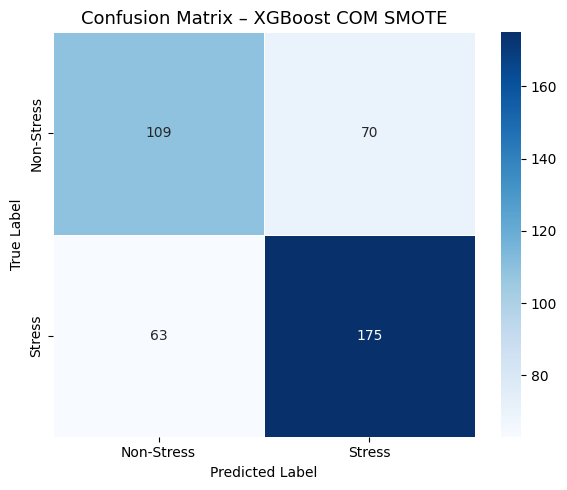

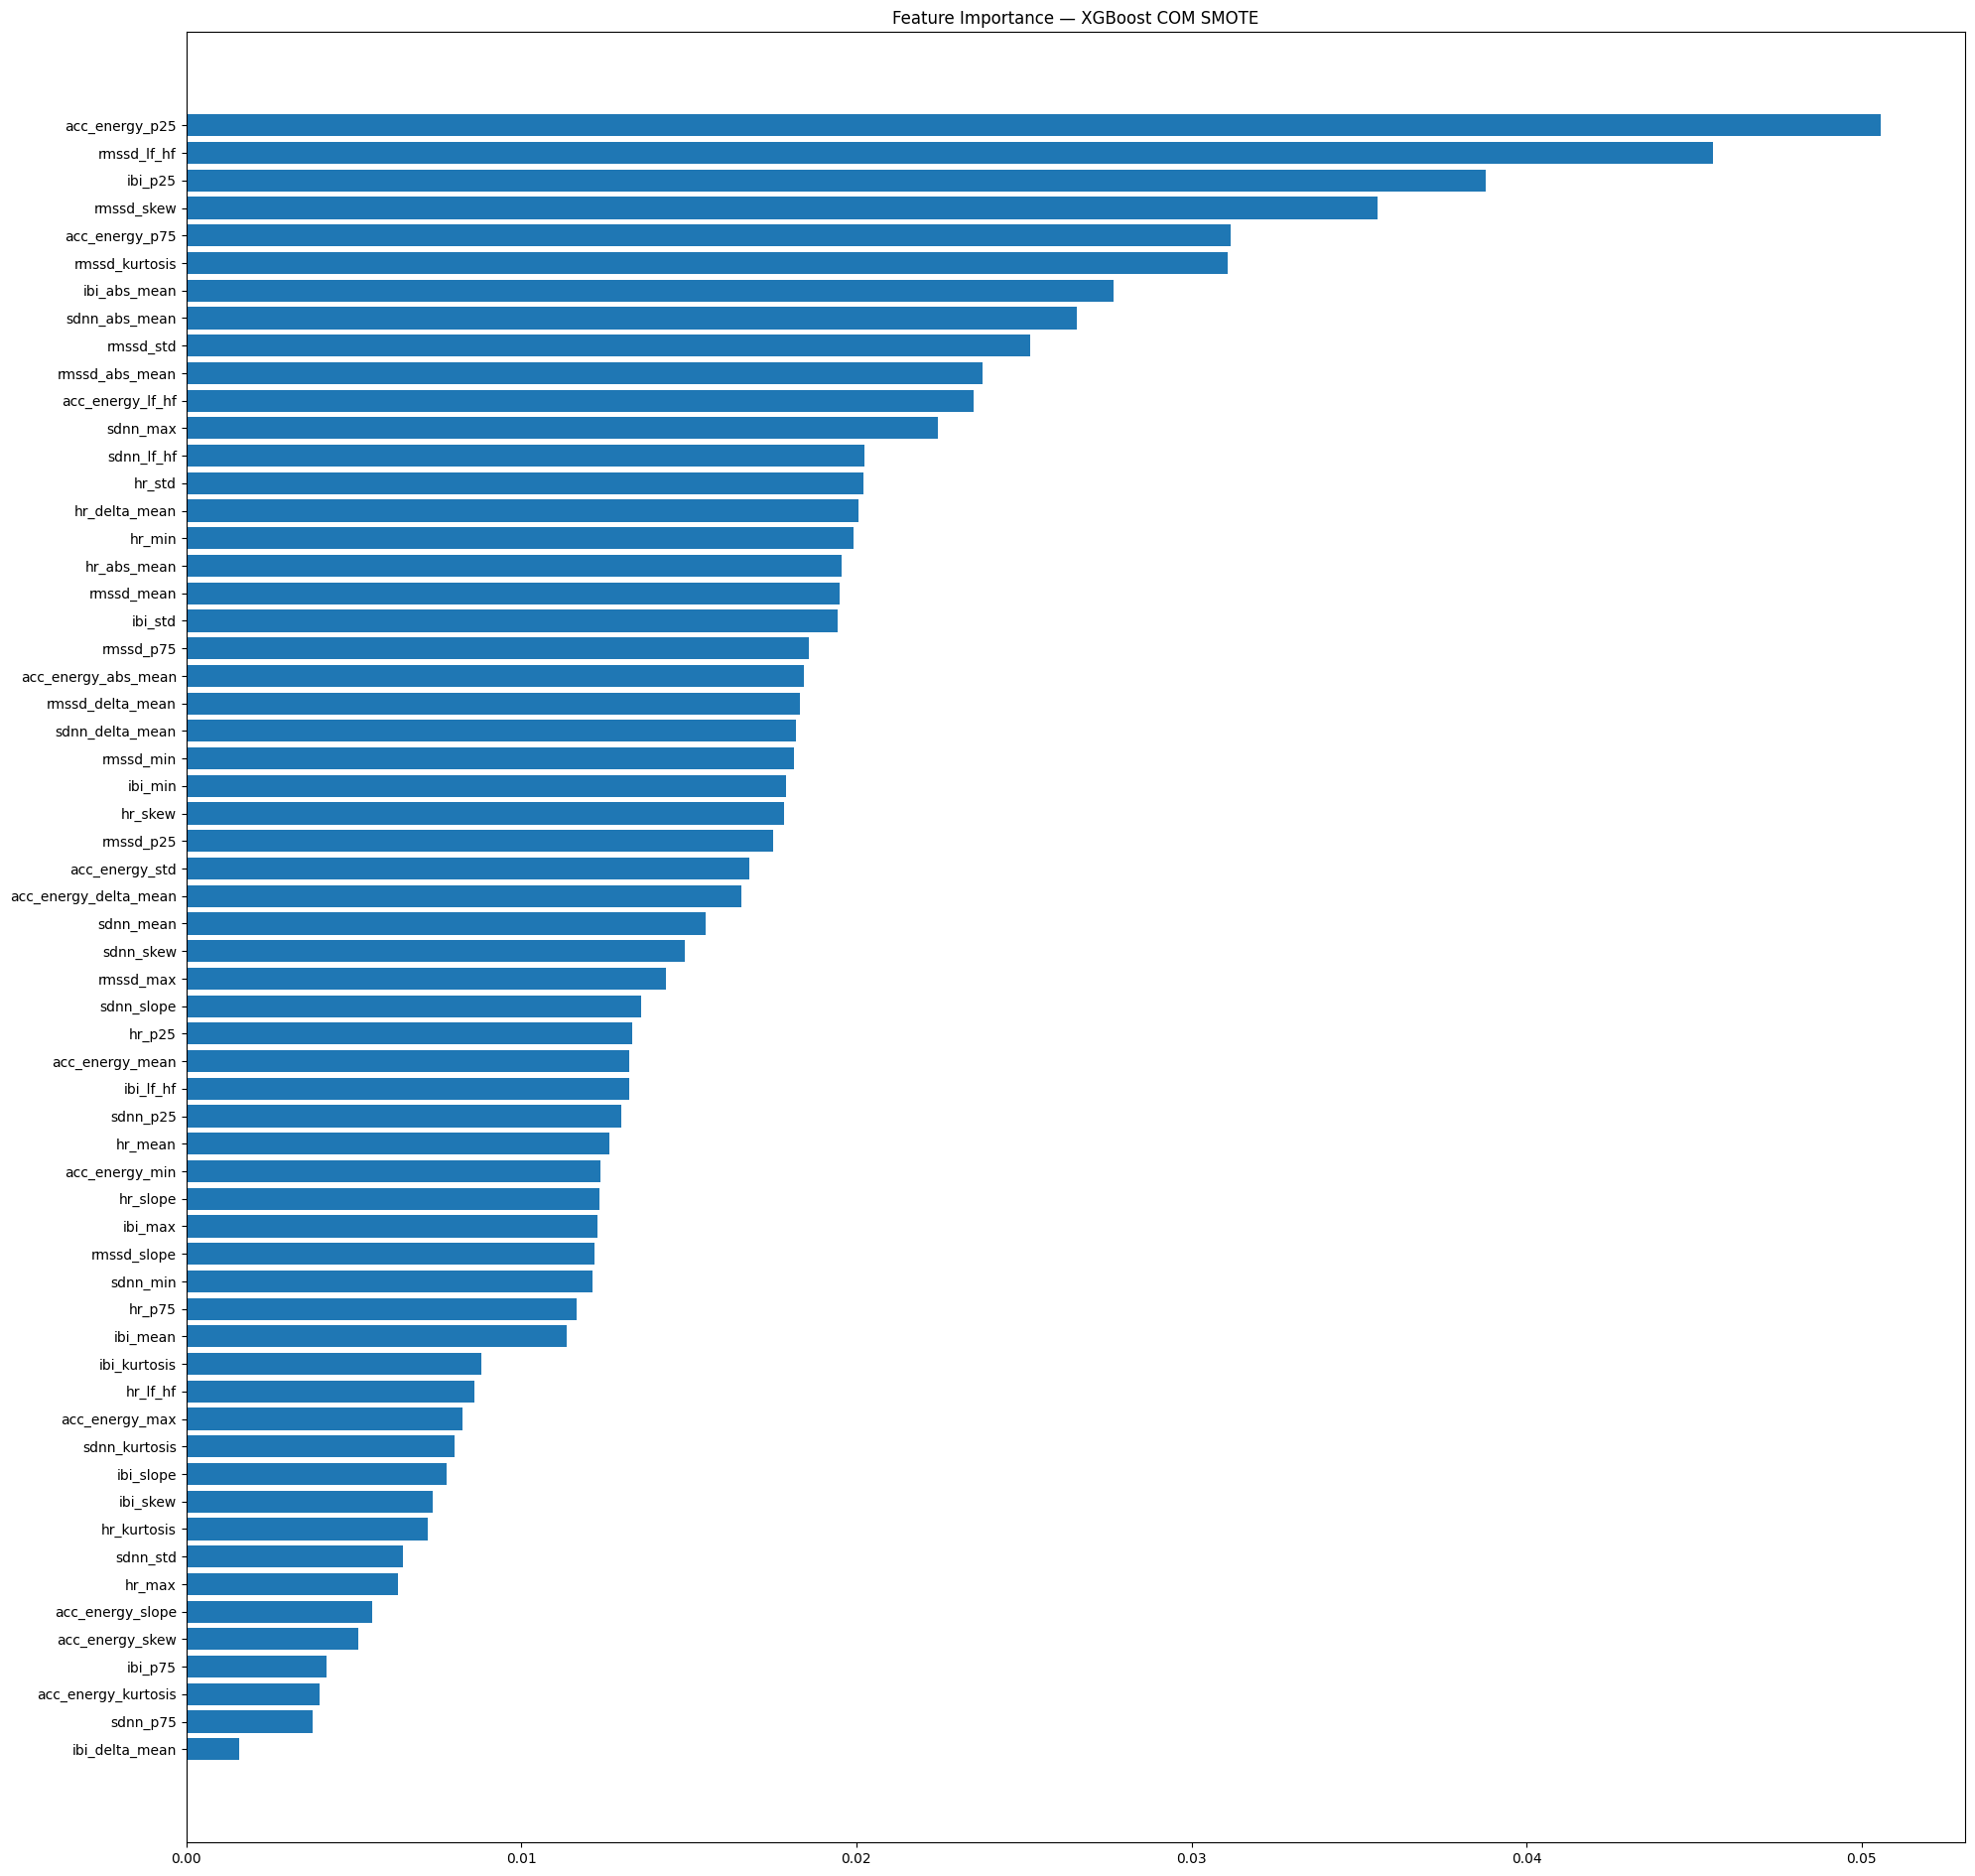

Guardado em: roc_data/xgb_smote.pkl

A correr XGBoost SEM SMOTE...
Novo melhor F1: 0.655 -> {'n_estimators': 75, 'max_depth': 5, 'learning_rate': 0.05}
Novo melhor F1: 0.681 -> {'n_estimators': 75, 'max_depth': 5, 'learning_rate': 0.1}
Novo melhor F1: 0.692 -> {'n_estimators': 75, 'max_depth': 5, 'learning_rate': 0.2}
Novo melhor F1: 0.693 -> {'n_estimators': 75, 'max_depth': 7, 'learning_rate': 0.2}
Novo melhor F1: 0.697 -> {'n_estimators': 100, 'max_depth': 5, 'learning_rate': 0.2}
Novo melhor F1: 0.703 -> {'n_estimators': 200, 'max_depth': 5, 'learning_rate': 0.2}
Melhores parâmetros SEM SMOTE: {'n_estimators': 200, 'max_depth': 5, 'learning_rate': 0.2}
              precision    recall  f1-score   support

           0       0.61      0.55      0.58       179
           1       0.69      0.74      0.71       238

    accuracy                           0.66       417
   macro avg       0.65      0.65      0.65       417
weighted avg       0.66      0.66      0.66       417

ROC-AUC:

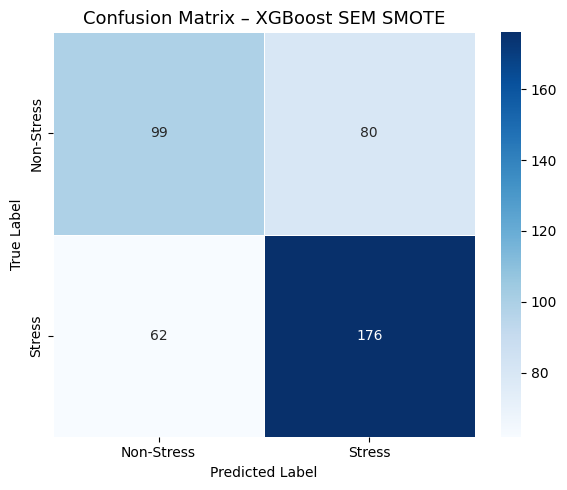

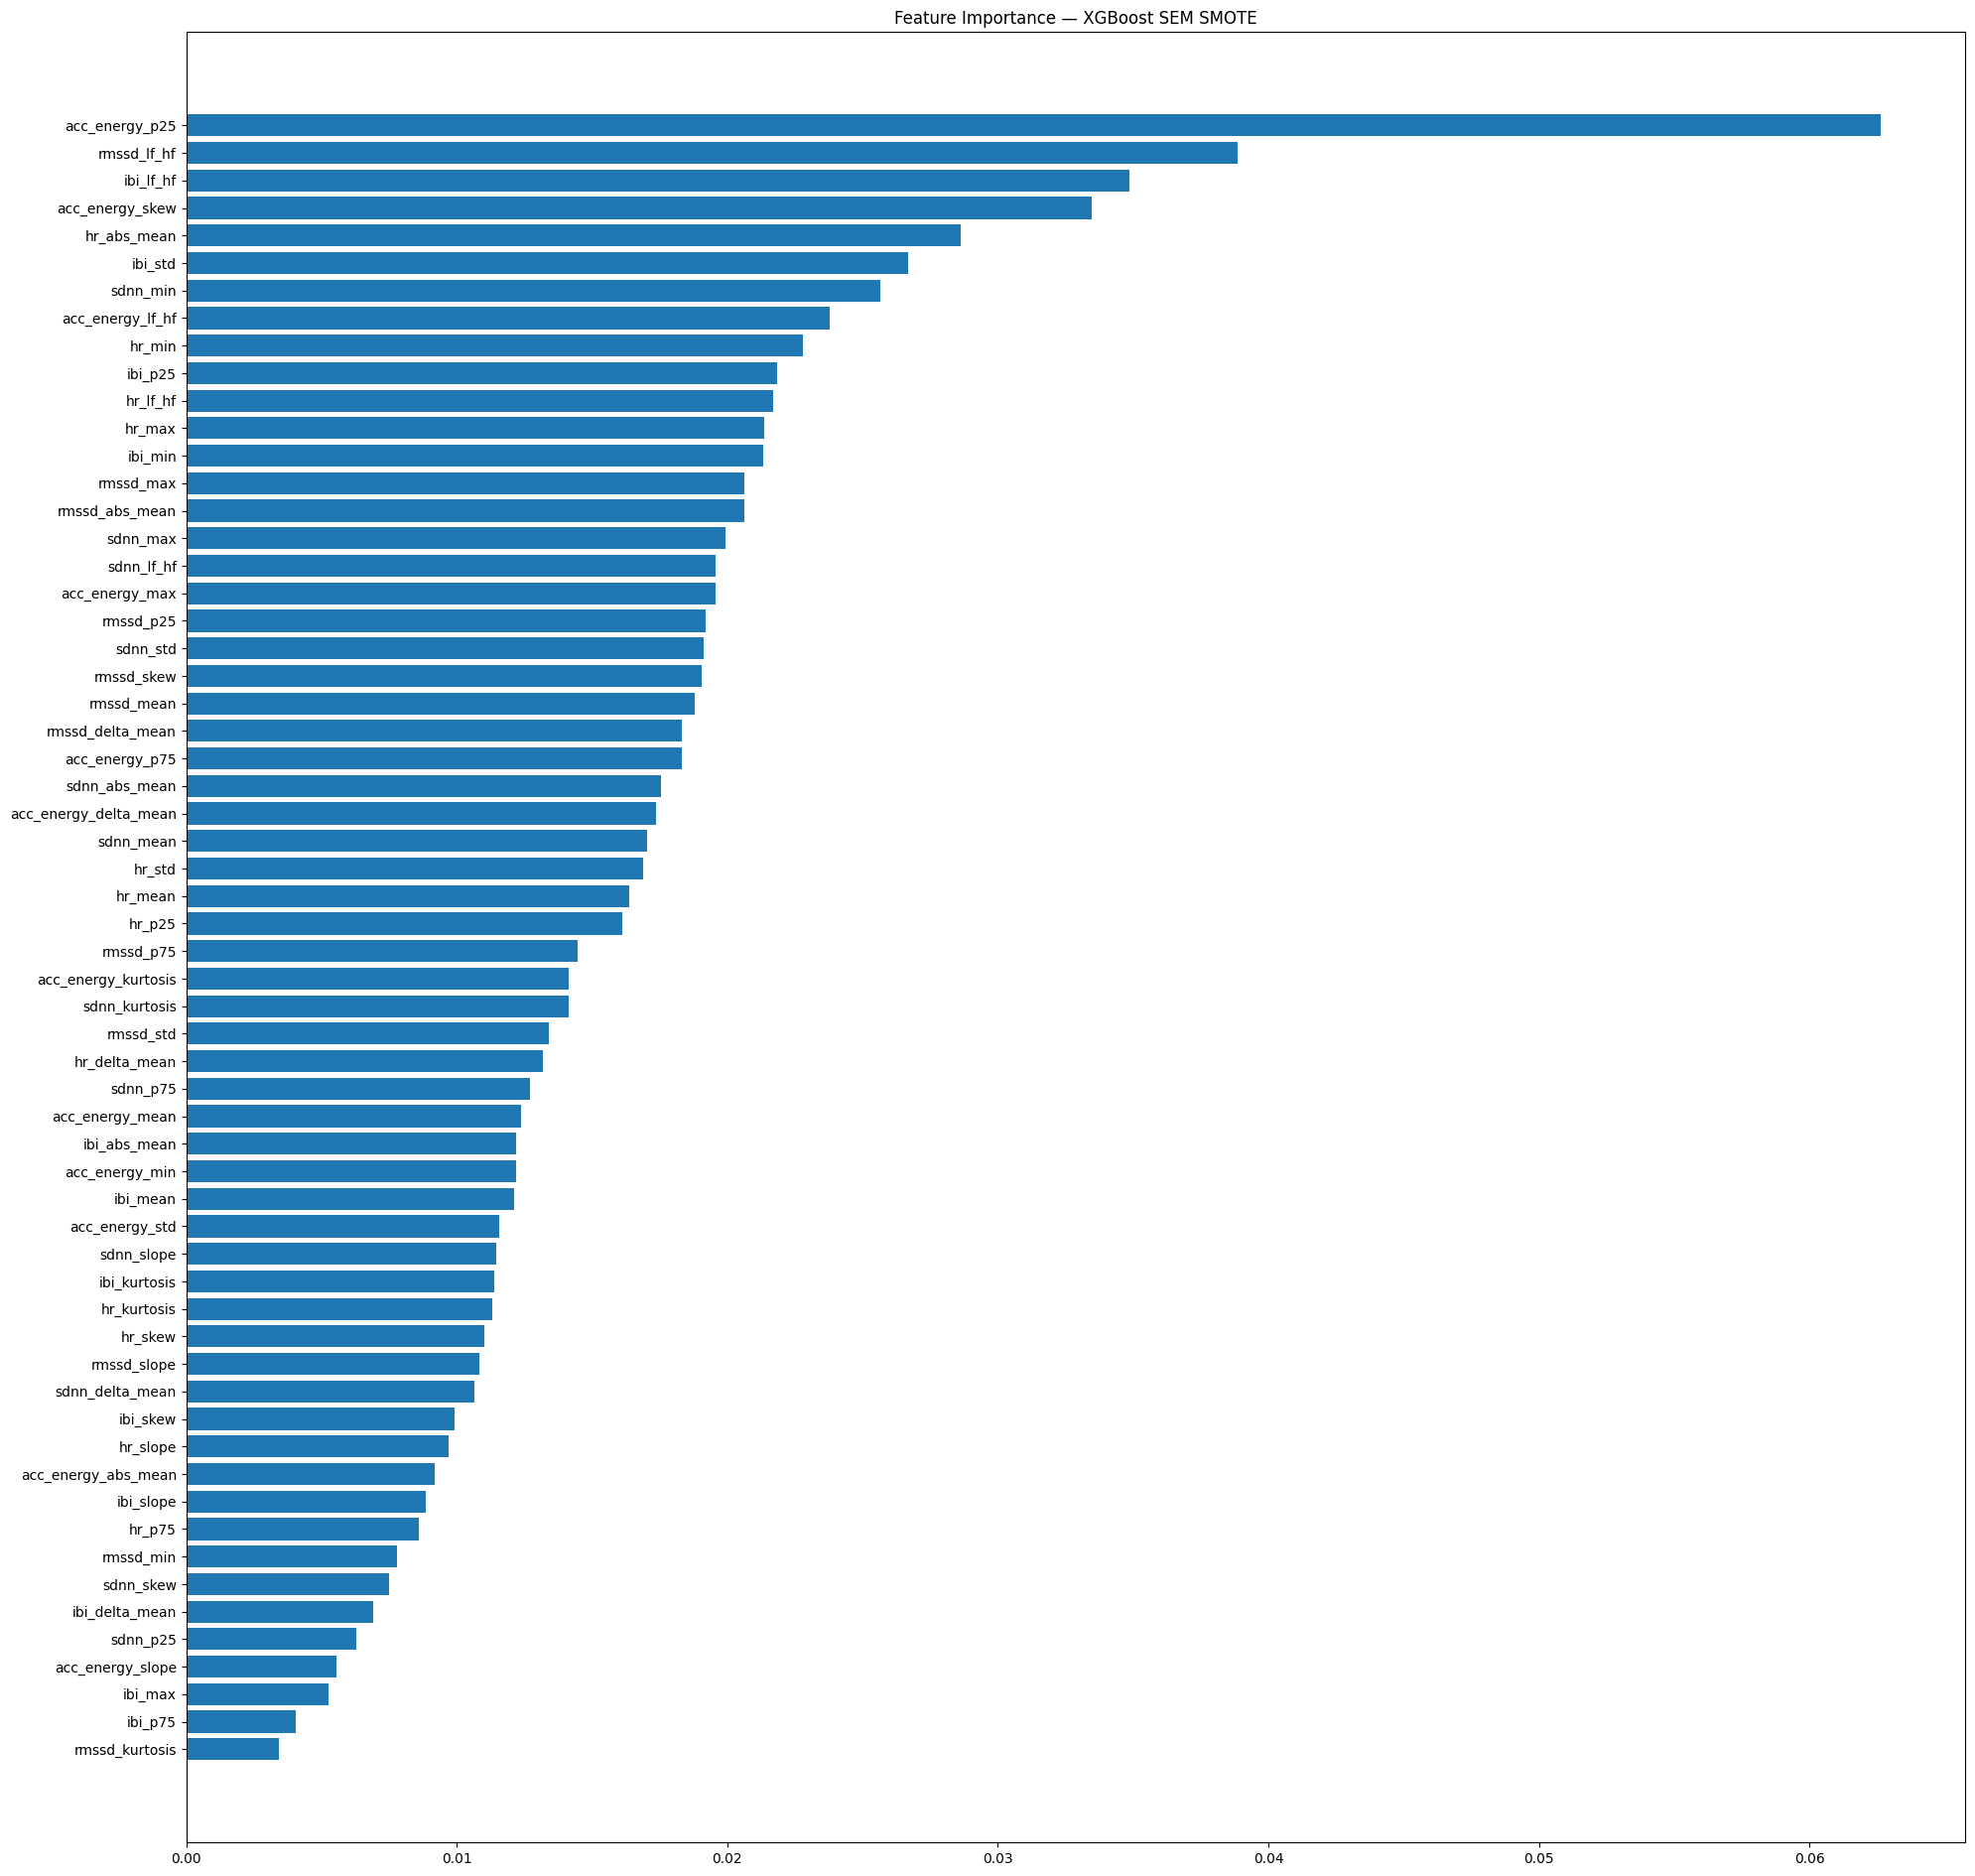

Guardado em: roc_data/xgb_no_smote.pkl


In [19]:
run_xgb(use_smote=True)
run_xgb(use_smote=False)

# Modelo LightGBM

In [20]:
optuna.logging.set_verbosity(optuna.logging.WARNING)
warnings.filterwarnings('ignore')
logo = LeaveOneGroupOut()

In [21]:
def objective(trial, use_smote):
    params = {
        'n_estimators':      trial.suggest_int('n_estimators', 100, 500),
        'max_depth':         trial.suggest_int('max_depth', 3, 10),
        'learning_rate':     trial.suggest_float('learning_rate', 0.01, 0.2),
        'num_leaves':        trial.suggest_int('num_leaves', 31, 127),
        'min_child_samples': trial.suggest_int('min_child_samples', 5, 50),
        'subsample':         trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree':  trial.suggest_float('colsample_bytree', 0.6, 1.0),
    }
    f1_scores = []
    for train_idx, test_idx in logo.split(X, y, groups):
        X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
        y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

        scaler  = StandardScaler()
        imputer = SimpleImputer(strategy='mean')
        X_tr = imputer.fit_transform(scaler.fit_transform(X_train))
        X_te = imputer.transform(scaler.transform(X_test))

        if use_smote:
            X_tr, y_train = SMOTE(random_state=42).fit_resample(X_tr, y_train)

        model = LGBMClassifier(**params, device='cpu', random_state=42, verbose=-1)
        model.fit(X_tr, y_train)
        f1_scores.append(f1_score(y_test, model.predict(X_te), zero_division=0))
    return np.mean(f1_scores)

In [22]:
def evaluate_lgbm(X, y, groups, best_params, use_smote=True):
    logo = LeaveOneGroupOut()
    all_y_true, all_y_pred, all_y_probs = [], [], []
    fold_f1s, fold_mccs, all_cms = [], [], []
    last_model = None

    for train_idx, test_idx in logo.split(X, y, groups):
        X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
        y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

        scaler  = StandardScaler()
        imputer = SimpleImputer(strategy='mean')
        X_train = imputer.fit_transform(scaler.fit_transform(X_train))
        X_test  = imputer.transform(scaler.transform(X_test))

        if use_smote:
            X_train, y_train = SMOTE(random_state=42).fit_resample(X_train, y_train)

        model = LGBMClassifier(**best_params, device='cpu', random_state=42, verbose=-1)
        model.fit(X_train, y_train)
        last_model = model

        y_pred = model.predict(X_test)
        y_prob = model.predict_proba(X_test)[:, 1]

        all_y_true.extend(y_test)
        all_y_pred.extend(y_pred)
        all_y_probs.extend(y_prob)
        fold_f1s.append(f1_score(y_test, y_pred, zero_division=0))
        fold_mccs.append(matthews_corrcoef(y_test, y_pred))
        all_cms.append(confusion_matrix(y_test, y_pred))

    return {
        'y_test':   np.array(all_y_true),
        'y_pred':   np.array(all_y_pred),
        'y_prob':   np.array(all_y_probs),
        'f1':       np.mean(fold_f1s),
        'f1_std':   np.std(fold_f1s),
        'accuracy': accuracy_score(all_y_true, all_y_pred),
        'bal_acc':  balanced_accuracy_score(all_y_true, all_y_pred),
        'mcc':      np.mean(fold_mccs),
        'roc_auc':  roc_auc_score(all_y_true, all_y_probs),
        'cm':       np.sum(all_cms, axis=0),
        'model':    last_model,
    }

In [23]:
def run_lgbm(use_smote):
    label = "COM SMOTE" if use_smote else "SEM SMOTE"
    print(f"\n{'='*50}\nA correr Optuna LightGBM {label}...\n{'='*50}")

    # Optuna
    optuna.logging.set_verbosity(optuna.logging.WARNING)
    study = optuna.create_study(direction='maximize')
    study.optimize(lambda trial: objective(trial, use_smote), n_trials=50)
    best_params = study.best_params
    print(f"Melhores parâmetros {label}: {best_params}")

    # Avaliação
    res = evaluate_lgbm(X, y, groups, best_params, use_smote=use_smote)

    # Métricas
    print(classification_report(res['y_test'], res['y_pred'], target_names=['Negativo', 'Positivo']))
    print(f"ROC-AUC:            {res['roc_auc']:.3f}")
    print(f"Balanced Accuracy:  {res['bal_acc']:.3f}")
    print(f"MCC:                {res['mcc']:.3f}")
    print(f"F1 Std (por fold):  {res['f1_std']:.3f}")

    # Confusion Matrix
    fig, ax = plt.subplots(figsize=(6, 5))
    sns.heatmap(
        res['cm'], annot=True, fmt='d', cmap='Greens',
        xticklabels=['Negativo', 'Positivo'],
        yticklabels=['Negativo', 'Positivo'],
        linewidths=0.5, ax=ax
    )
    ax.set_title(f'Confusion Matrix – LightGBM {label}', fontsize=13)
    ax.set_xlabel('Predição'); ax.set_ylabel('Realidade')
    plt.tight_layout(); plt.show()

    # Feature Importance — todas
    importances = res['model'].feature_importances_
    indices     = np.argsort(importances)
    plt.figure(figsize=(20, 19))
    plt.barh(np.array(feature_cols)[indices], importances[indices])
    plt.title(f"Feature Importance — LightGBM {label}")
    plt.tight_layout(); plt.show()

    # Feature Importance — Questionário
    quest_cols = [c for c in ['age', 'gender', 'coffee_last_hour', 'sports', 'smoker', 'ill']
                if c in list(feature_cols)]
    if quest_cols:
        quest_indices = [list(feature_cols).index(c) for c in quest_cols]
        quest_importances = res['model'].feature_importances_[quest_indices]
        indices = np.argsort(quest_importances)
        plt.figure(figsize=(8, 5))
        plt.barh(np.array(quest_cols)[indices], quest_importances[indices])
        plt.title('Feature Importance — Questionário')
        plt.tight_layout()
        plt.show()

    # Guardar pkl
    smote_tag = 'smote' if use_smote else 'no_smote'
    roc_data  = {k: v for k, v in res.items() if k != 'model'}
    roc_data.update({'smote': use_smote, 'best_params': best_params, 'model': 'LightGBM'})
    os.makedirs('roc_data', exist_ok=True)
    fname = f'roc_data/lgbm_{smote_tag}.pkl'
    with open(fname, 'wb') as f:
        pickle.dump(roc_data, f)
    print(f"Guardado em: {fname}")


A correr Optuna LightGBM COM SMOTE...
Melhores parâmetros COM SMOTE: {'n_estimators': 454, 'max_depth': 7, 'learning_rate': 0.12706807031373615, 'num_leaves': 121, 'min_child_samples': 45, 'subsample': 0.7999986279638241, 'colsample_bytree': 0.9309138130025181}
              precision    recall  f1-score   support

    Negativo       0.64      0.60      0.62       179
    Positivo       0.71      0.74      0.73       238

    accuracy                           0.68       417
   macro avg       0.67      0.67      0.67       417
weighted avg       0.68      0.68      0.68       417

ROC-AUC:            0.734
Balanced Accuracy:  0.671
MCC:                0.351
F1 Std (por fold):  0.141


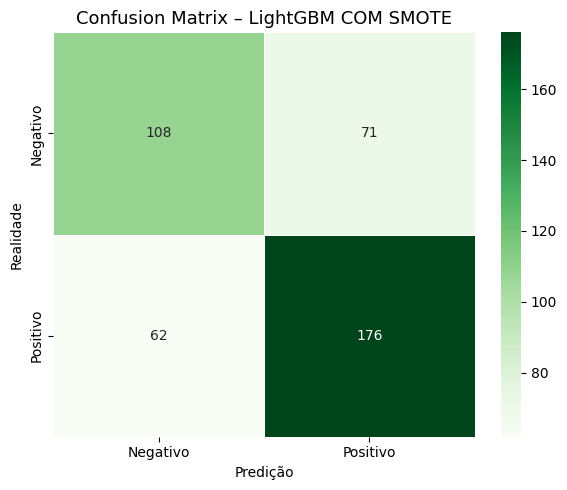

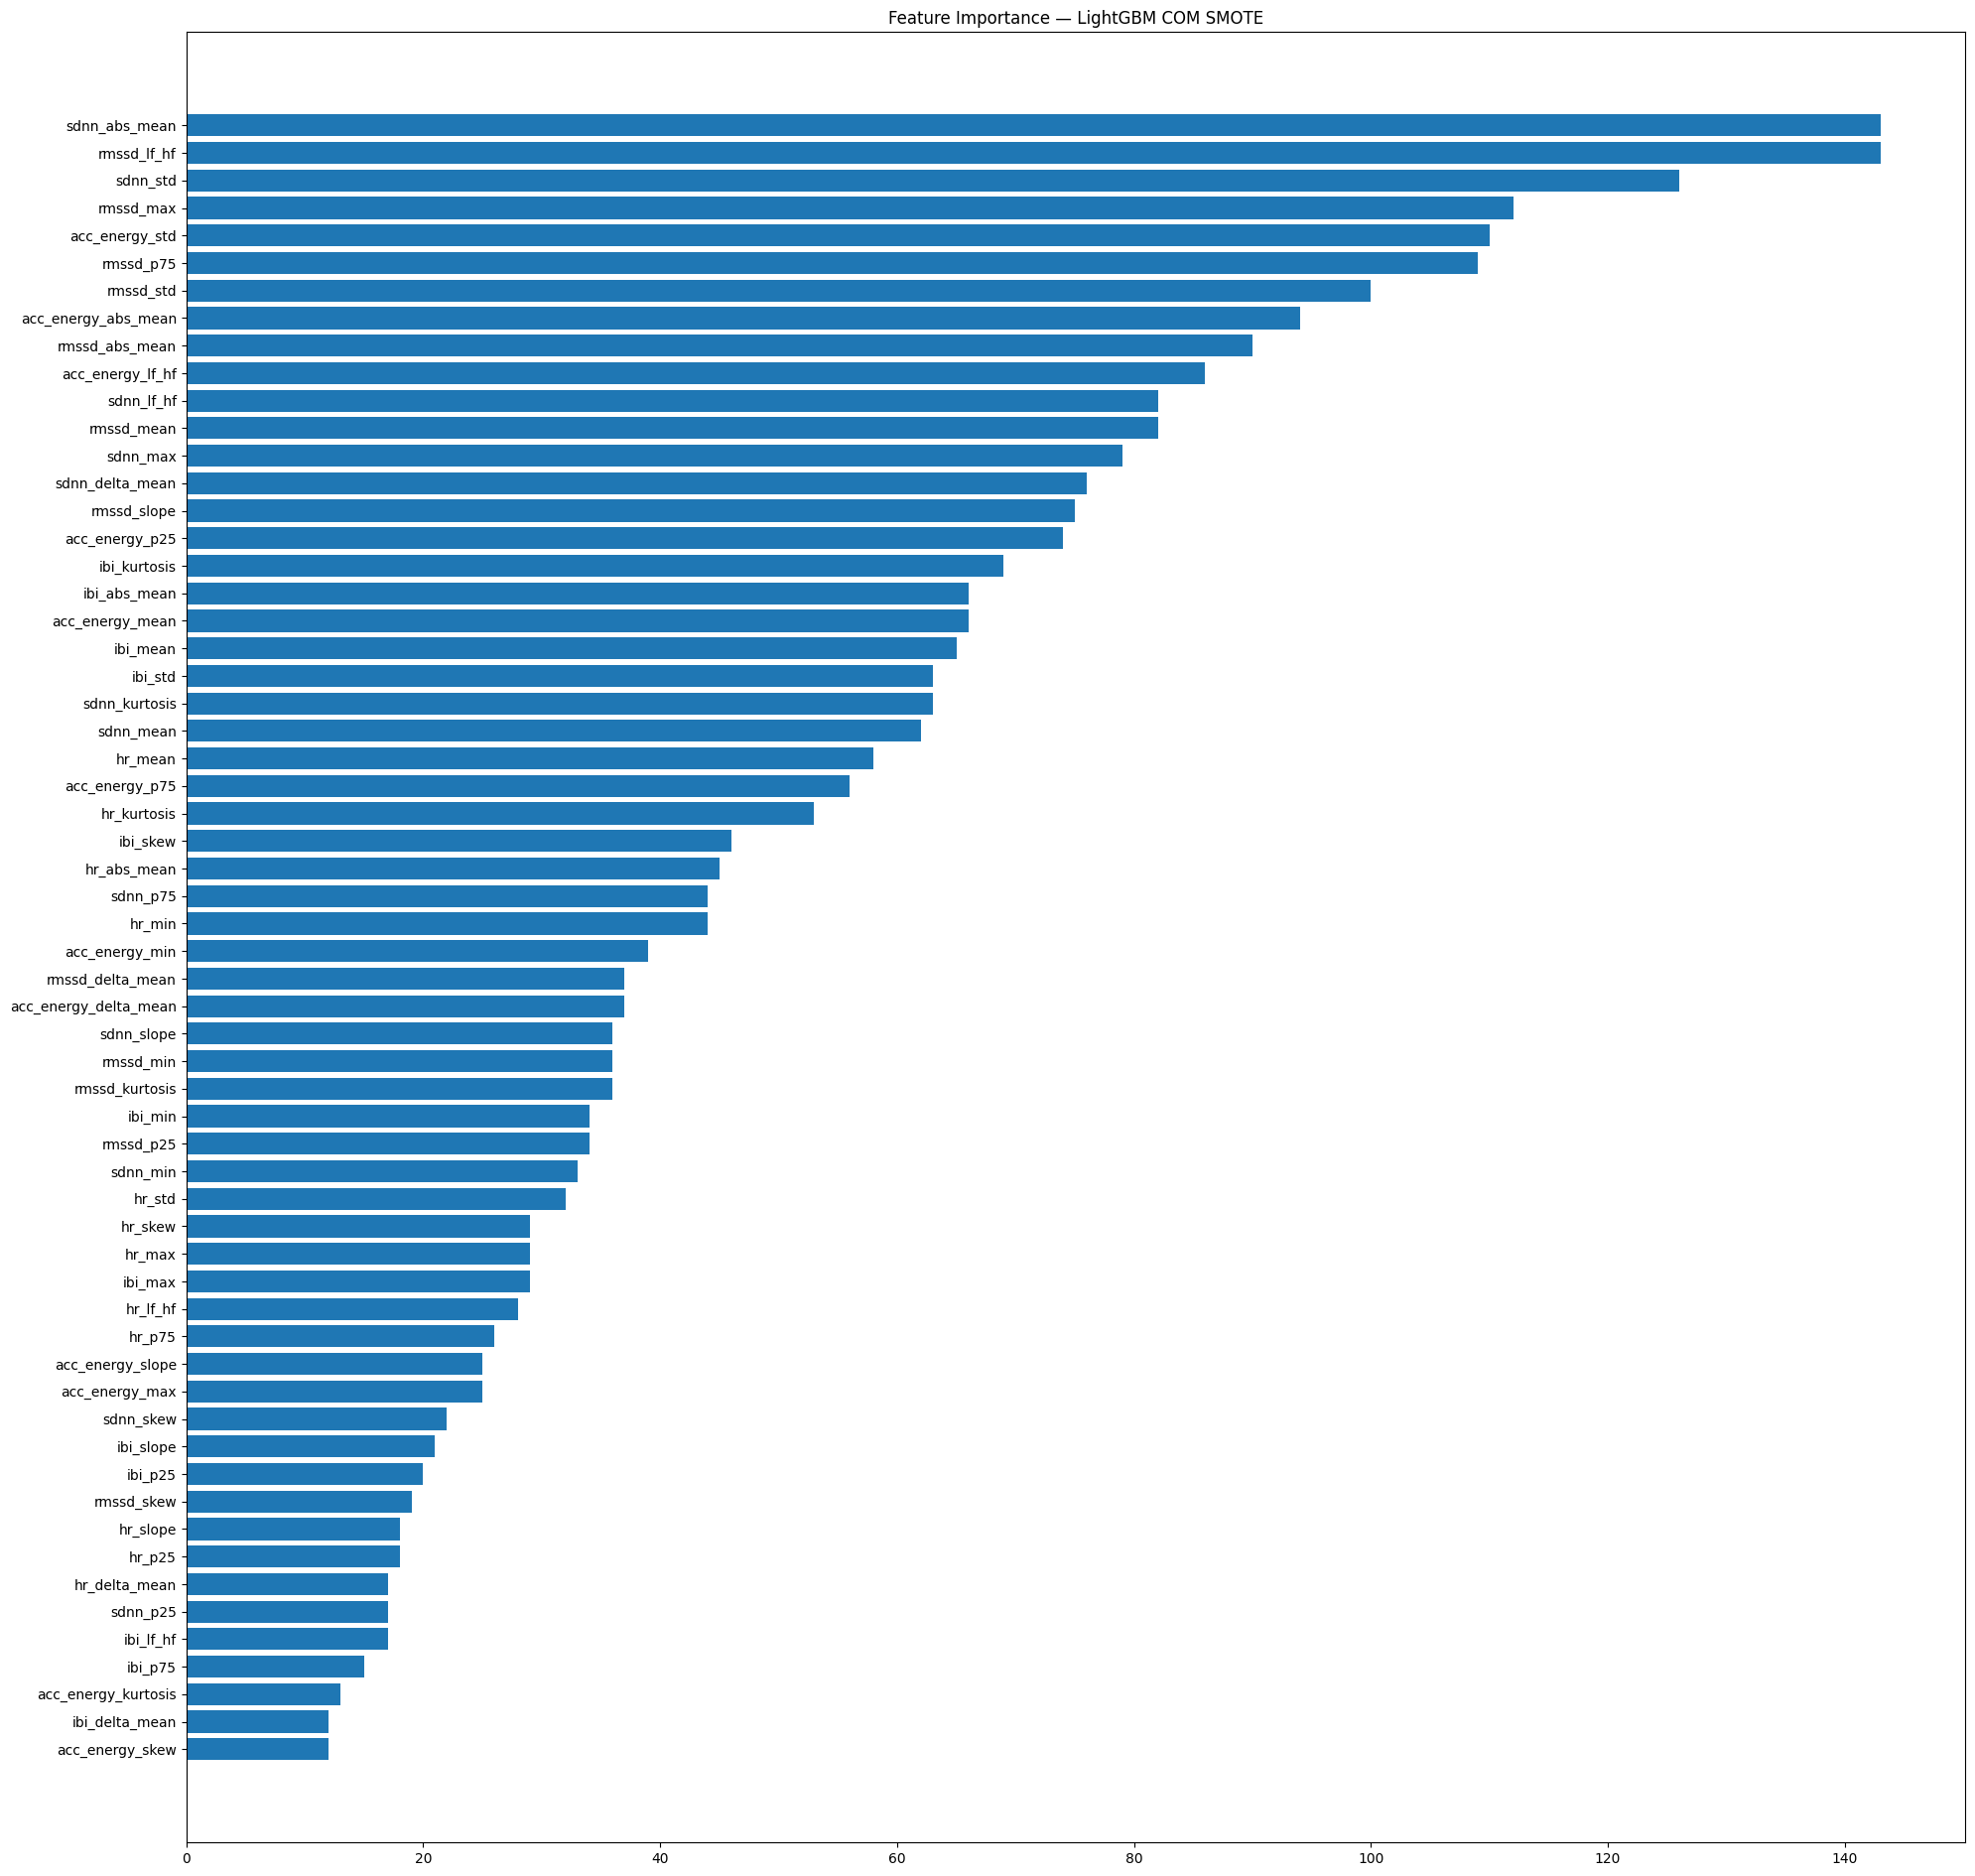

Guardado em: roc_data/lgbm_smote.pkl

A correr Optuna LightGBM SEM SMOTE...
Melhores parâmetros SEM SMOTE: {'n_estimators': 470, 'max_depth': 8, 'learning_rate': 0.0663025608547238, 'num_leaves': 80, 'min_child_samples': 29, 'subsample': 0.7712654196651417, 'colsample_bytree': 0.8086251224171346}
              precision    recall  f1-score   support

    Negativo       0.63      0.60      0.61       179
    Positivo       0.71      0.73      0.72       238

    accuracy                           0.67       417
   macro avg       0.67      0.66      0.67       417
weighted avg       0.67      0.67      0.67       417

ROC-AUC:            0.721
Balanced Accuracy:  0.664
MCC:                0.344
F1 Std (por fold):  0.117


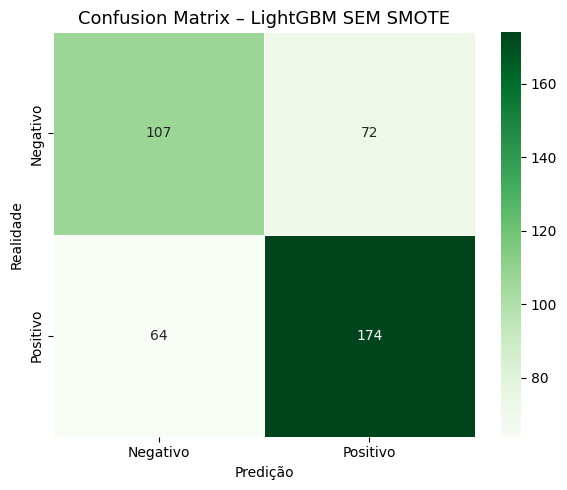

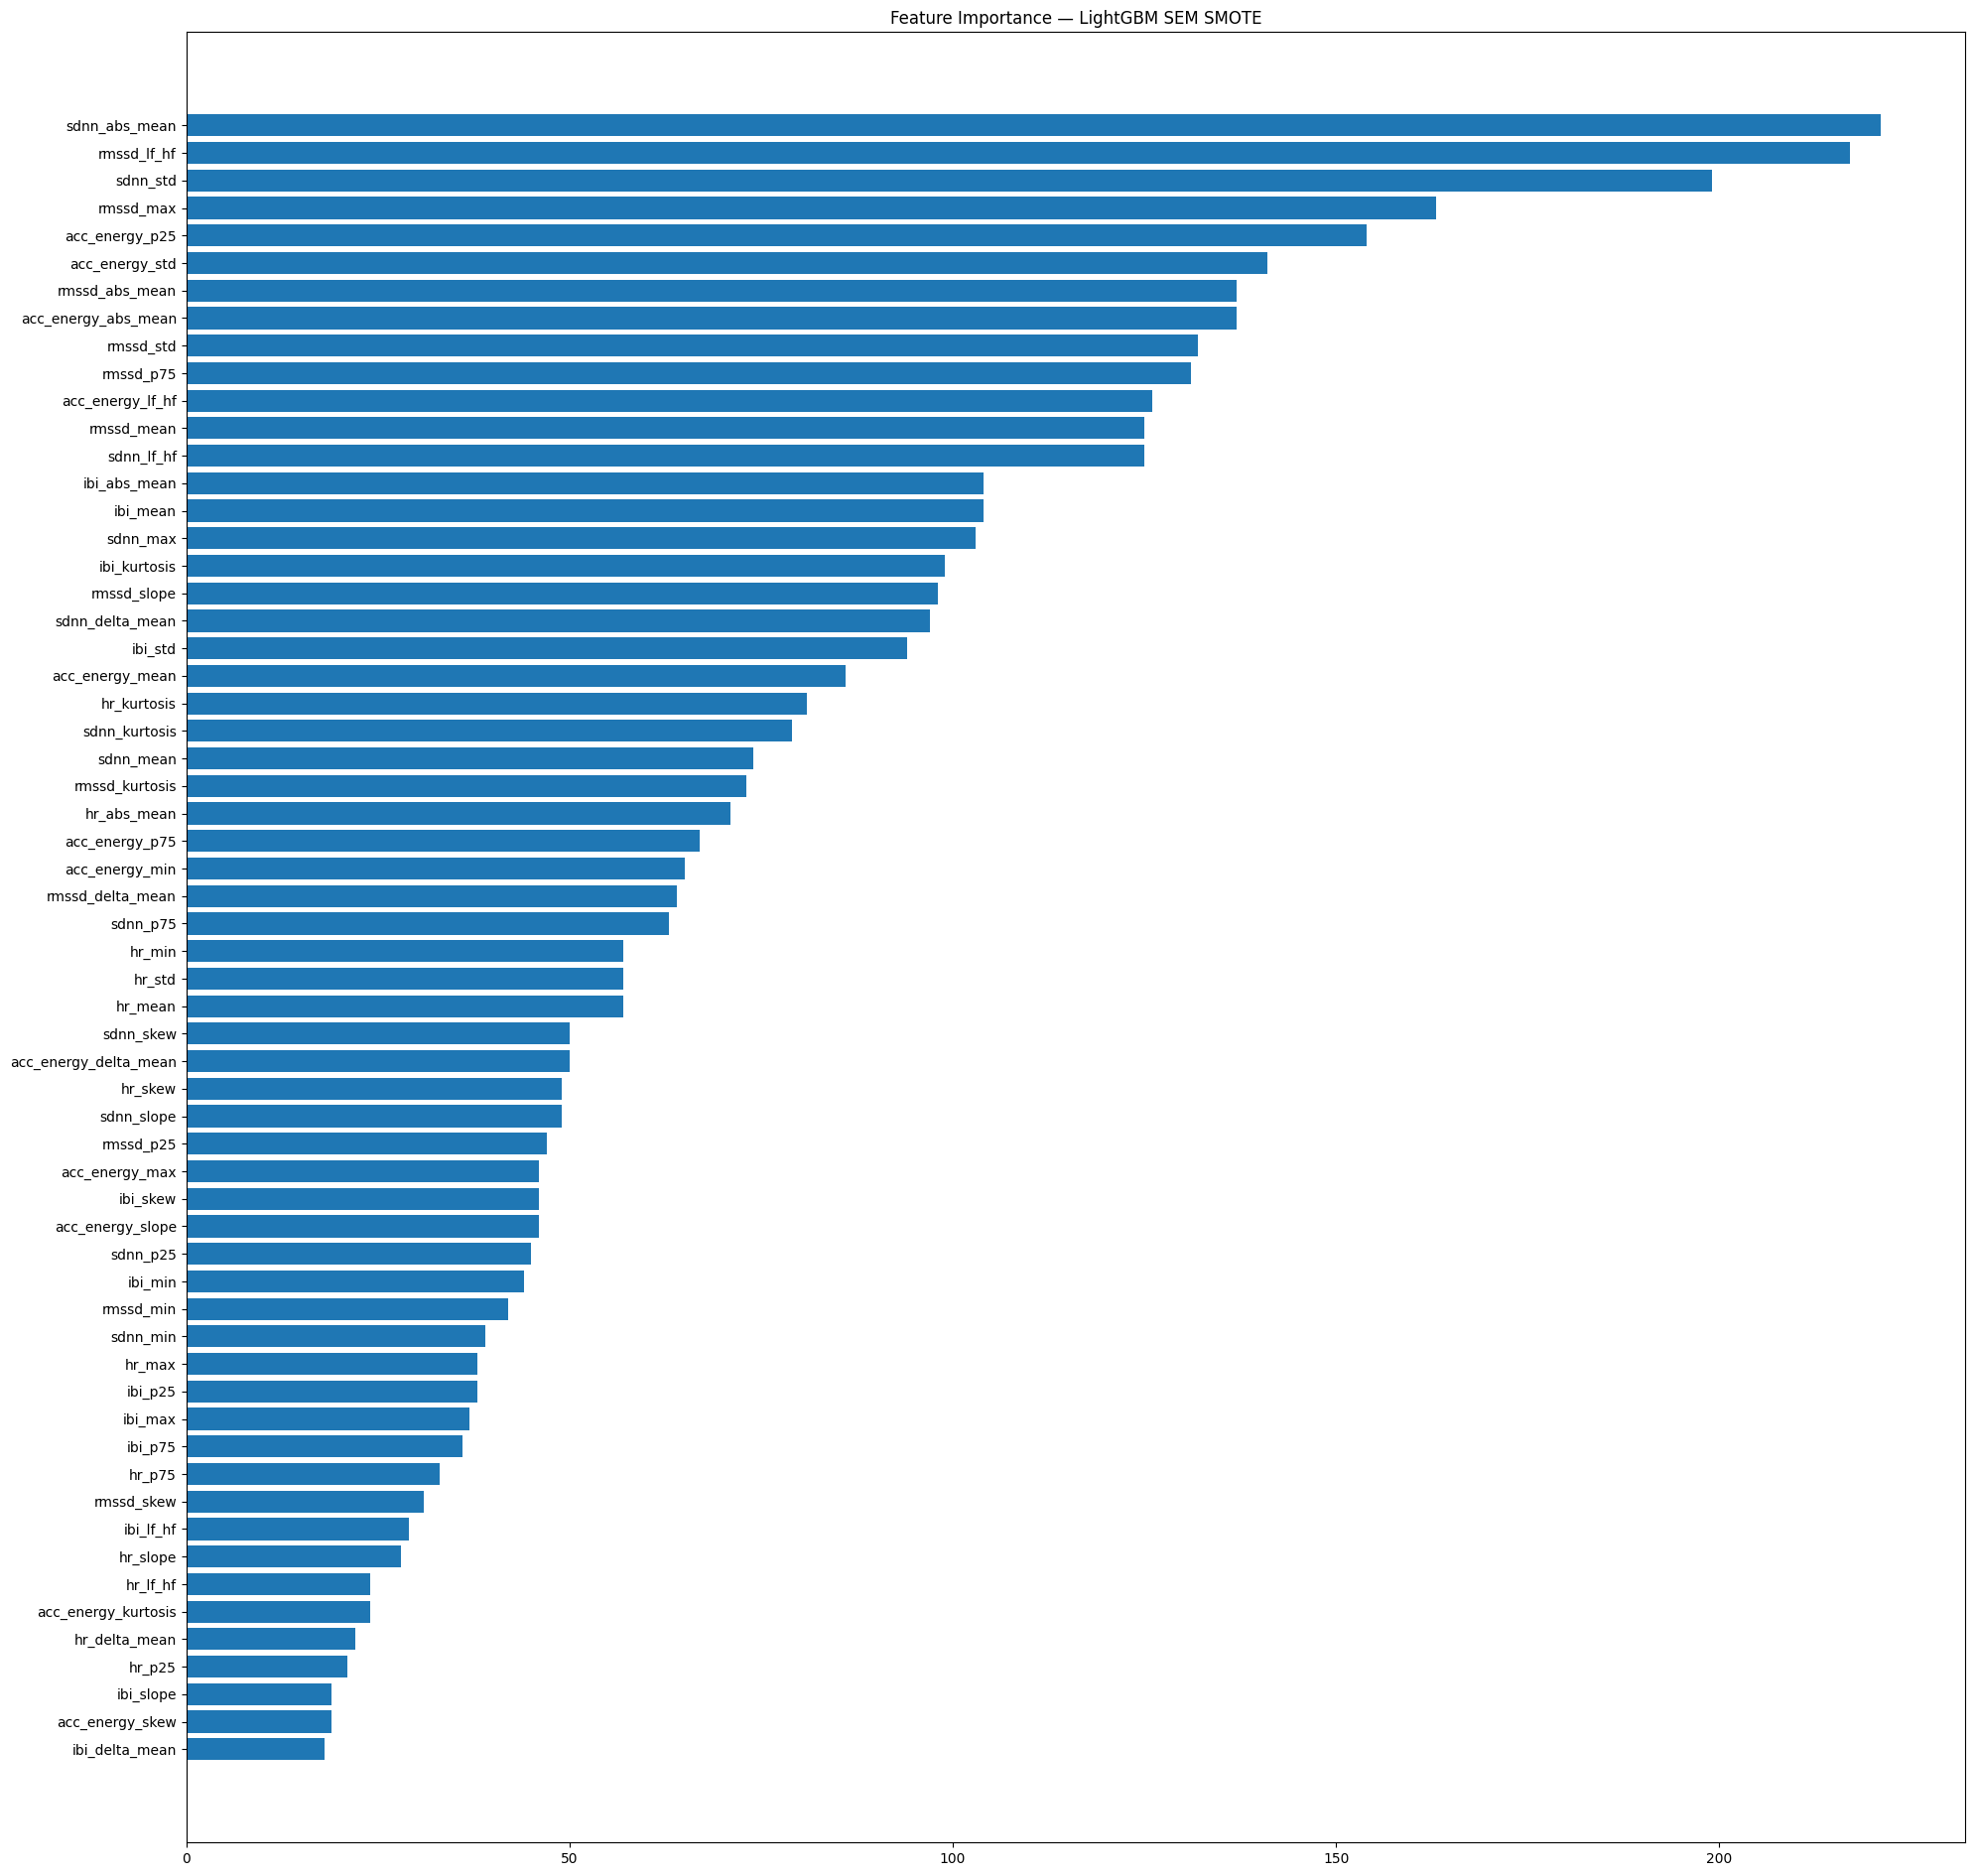

Guardado em: roc_data/lgbm_no_smote.pkl


In [24]:
run_lgbm(use_smote=True)
run_lgbm(use_smote=False)

In [ ]:
# F1 @ Youden-optimal threshold
from sklearn.metrics import roc_curve, f1_score
import numpy as np
_yt = np.array(y_test); _ys = np.array(y_score)
_fpr, _tpr, _thr = roc_curve(_yt, _ys)
_t_opt = float(_thr[np.argmax(_tpr - _fpr)])
_f1opt = f1_score(_yt, (_ys >= _t_opt).astype(int), average='macro', zero_division=0)
print(f'F1@opt : {_f1opt:.3f}  (threshold={_t_opt:.3f})')